In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA



In [2]:

file_path ="/content/temporal_customer_dataset.csv"

temporal_dataset = pd.read_csv(file_path)

temporal_dataset["SnapshotDate"] = pd.to_datetime(
    temporal_dataset["SnapshotDate"]
)

temporal_dataset["CustomerID"] = (
    temporal_dataset["CustomerID"].astype("string")
)

print("Dataset loaded successfully!")
print("Shape:", temporal_dataset.shape)

temporal_dataset.head()

Dataset loaded successfully!
Shape: (48079, 18)


,CustomerID,Monetary,TotalQuantity,UniqueProducts,ActiveDays,FirstPurchase,LastPurchase,Frequency,AverageOrderValue,WeekendOrderCount,AvgDaysBetweenOrders,RecencyDays,FirstObservedPurchase,CustomerTenureDays,HasMultipleOrders,SnapshotDate,FutureOrders90D,Churn90D
0,12346.0,230.55,51,7,6,2009-12-14 08:34:00,2010-03-02 13:08:00,10,23.0550,0,8.687809,90,2009-12-14 08:34:00,168,1,2010-06-01,1,0
1,12349.0,1268.52,474,47,2,2010-04-29 13:20:00,2010-05-18 09:57:00,2,634.2600,0,18.859028,13,2010-04-29 13:20:00,32,1,2010-06-01,0,1
2,12355.0,488.21,303,22,1,2010-05-21 11:59:00,2010-05-21 11:59:00,1,488.2100,0,NaN,10,2010-05-21 11:59:00,10,0,2010-06-01,0,1
3,12358.0,1429.83,309,17,1,2009-12-08 07:59:00,2009-12-08 07:59:00,1,1429.8300,0,NaN,174,2009-12-08 07:59:00,174,0,2010-06-01,1,0
4,12359.0,1522.23,777,65,4,2009-12-05 13:32:00,2010-03-23 08:55:00,4,380.5575,1,35.935880,69,2009-12-05 13:32:00,177,1,2010-06-01,1,0


In [3]:
latest_snapshot_date = temporal_dataset["SnapshotDate"].max()

print("Latest Snapshot Date:", latest_snapshot_date)

Latest Snapshot Date: 2011-09-01 00:00:00


In [4]:
customer_data = temporal_dataset[
    temporal_dataset["SnapshotDate"] == latest_snapshot_date
].copy()

print("Customer Dataset Shape:", customer_data.shape)

print(
    "Unique Customers:",
    customer_data["CustomerID"].nunique()
)

customer_data.head()

Customer Dataset Shape: (2772, 18)
Unique Customers: 2772


,CustomerID,Monetary,TotalQuantity,UniqueProducts,ActiveDays,FirstPurchase,LastPurchase,Frequency,AverageOrderValue,WeekendOrderCount,AvgDaysBetweenOrders,RecencyDays,FirstObservedPurchase,CustomerTenureDays,HasMultipleOrders,SnapshotDate,FutureOrders90D,Churn90D
45307,12347.0,1603.68,956,50,3,2011-04-07 10:43:00,2011-08-02 08:48:00,3,534.56,0,58.460069,29,2010-10-31 14:20:00,304,1,2011-09-01,1,0
45308,12348.0,367.00,269,5,1,2011-04-05 10:47:00,2011-04-05 10:47:00,1,367.00,0,NaN,148,2010-09-27 14:59:00,338,0,2011-09-01,1,0
45309,12352.0,280.66,127,8,2,2011-03-17 16:00:00,2011-03-22 16:08:00,2,140.33,0,5.005556,162,2010-11-12 10:20:00,292,1,2011-09-01,3,0
45310,12353.0,89.00,20,4,1,2011-05-19 17:47:00,2011-05-19 17:47:00,1,89.00,0,NaN,104,2010-10-27 12:44:00,308,0,2011-09-01,0,1
45311,12354.0,1079.40,530,58,1,2011-04-21 13:11:00,2011-04-21 13:11:00,1,1079.40,0,NaN,132,2011-04-21 13:11:00,132,0,2011-09-01,0,1


In [5]:
rfm = customer_data[
    [
        "CustomerID",
        "RecencyDays",
        "Frequency",
        "Monetary"
    ]
].copy()

rfm.rename(
    columns={
        "RecencyDays": "Recency",
        "Frequency": "Frequency",
        "Monetary": "Monetary"
    },
    inplace=True
)

print("RFM Dataset Shape:", rfm.shape)

rfm.head()

RFM Dataset Shape: (2772, 4)


,CustomerID,Recency,Frequency,Monetary
45307,12347.0,29,3,1603.68
45308,12348.0,148,1,367.00
45309,12352.0,162,2,280.66
45310,12353.0,104,1,89.00
45311,12354.0,132,1,1079.40


           Recency    Frequency       Monetary
count  2772.000000  2772.000000    2772.000000
mean     65.591631     2.827922    1280.830722
std      50.444025     4.123890    4409.289419
min       0.000000     1.000000       2.900000
25%      21.000000     1.000000     248.507500
50%      55.000000     2.000000     488.335000
75%     103.000000     3.000000    1113.340000
max     178.000000    83.000000  118489.920000

Missing Values:
CustomerID    0
Recency       0
Frequency     0
Monetary      0
dtype: int64


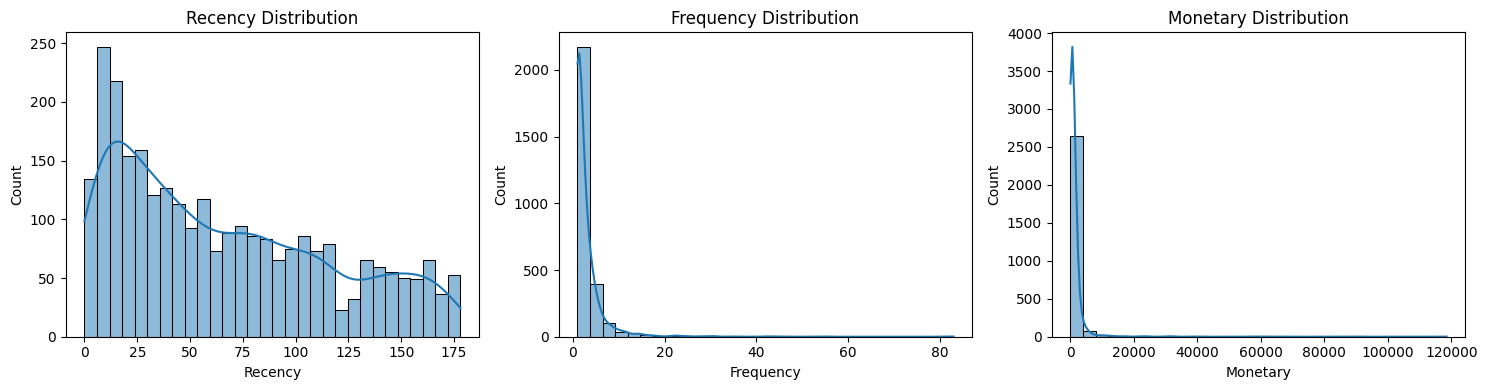

In [9]:
print(rfm[["Recency", "Frequency", "Monetary"]].describe())

print("\nMissing Values:")
print(rfm.isnull().sum())

# visually display
plt.figure(figsize=(15, 4))

for i, column in enumerate(
    ["Recency", "Frequency", "Monetary"]
):

    plt.subplot(1, 3, i + 1)

    sns.histplot(
        rfm[column],
        kde=True,
        bins=30
    )

    plt.title(f"{column} Distribution")

plt.tight_layout()
plt.show()

Log transformation completed!


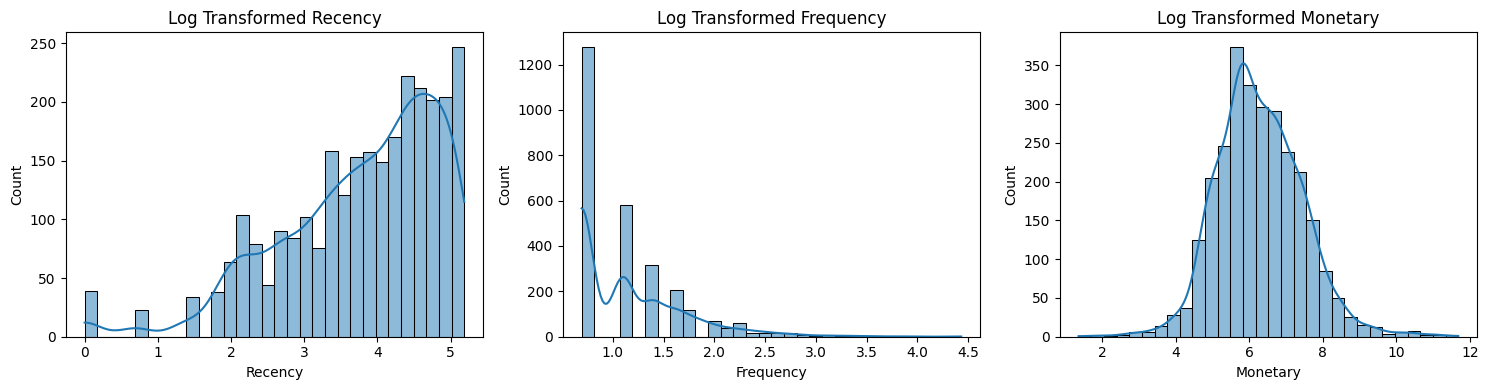

In [10]:
rfm_features = rfm[
    ["Recency", "Frequency", "Monetary"]
].copy()

rfm_log = np.log1p(rfm_features)

print("Log transformation completed!")

rfm_log.head()

# visual
plt.figure(figsize=(15, 4))

for i, column in enumerate(
    ["Recency", "Frequency", "Monetary"]
):

    plt.subplot(1, 3, i + 1)

    sns.histplot(
        rfm_log[column],
        kde=True,
        bins=30
    )

    plt.title(f"Log Transformed {column}")

plt.tight_layout()
plt.show()

In [11]:
scaler = StandardScaler()

rfm_scaled = scaler.fit_transform(rfm_log)

rfm_scaled = pd.DataFrame(
    rfm_scaled,
    columns=["Recency", "Frequency", "Monetary"],
    index=rfm.index
)

print("Feature scaling completed!")

rfm_scaled.head()

Feature scaling completed!


,Recency,Frequency,Monetary
45307,-0.335139,0.456178,0.942333
45308,1.127016,-0.808605,-0.325638
45309,1.208943,-0.068755,-0.555866
45310,0.807731,-0.808605,-1.538223
45311,1.023384,-0.808605,0.601710


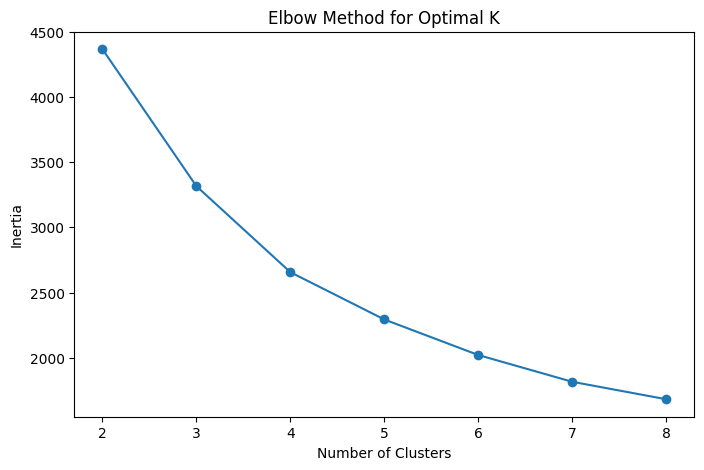

In [12]:
inertia_values = []

K = range(2, 9)

for k in K:

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )

    kmeans.fit(rfm_scaled)

    inertia_values.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))

plt.plot(
    list(K),
    inertia_values,
    marker="o"
)

plt.title("Elbow Method for Optimal K")
plt.xlabel("Number of Clusters")
plt.ylabel("Inertia")

plt.xticks(list(K))
plt.show()

In [13]:
silhouette_values = []

for k in range(2, 9):

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )

    labels = kmeans.fit_predict(rfm_scaled)

    score = silhouette_score(
        rfm_scaled,
        labels
    )

    silhouette_values.append(score)

    print(
        f"Clusters: {k}, "
        f"Silhouette Score: {score:.4f}"
    )

Clusters: 2, Silhouette Score: 0.4387
Clusters: 3, Silhouette Score: 0.3577
Clusters: 4, Silhouette Score: 0.3702
Clusters: 5, Silhouette Score: 0.3059
Clusters: 6, Silhouette Score: 0.2906
Clusters: 7, Silhouette Score: 0.2801
Clusters: 8, Silhouette Score: 0.2743


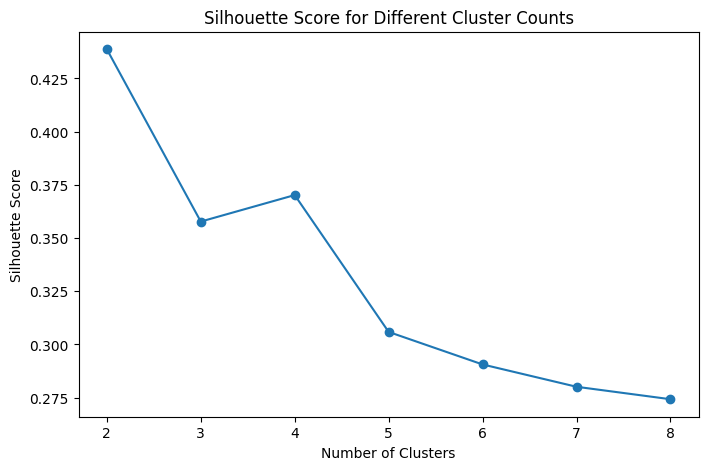

In [14]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(2, 9),
    silhouette_values,
    marker="o"
)

plt.title("Silhouette Score for Different Cluster Counts")
plt.xlabel("Number of Clusters")
plt.ylabel("Silhouette Score")

plt.xticks(range(2, 9))
plt.show()

In [15]:
OPTIMAL_K = 4

kmeans = KMeans(
    n_clusters=OPTIMAL_K,
    random_state=42,
    n_init=20
)

rfm["Cluster"] = kmeans.fit_predict(rfm_scaled)

print("K-Means clustering completed!")

rfm.head()

K-Means clustering completed!


,CustomerID,Recency,Frequency,Monetary,Cluster
45307,12347.0,29,3,1603.68,0
45308,12348.0,148,1,367.00,1
45309,12352.0,162,2,280.66,1
45310,12353.0,104,1,89.00,1
45311,12354.0,132,1,1079.40,1


Customers per Cluster:
Cluster
0     753
1    1243
2     353
3     423
Name: count, dtype: int64


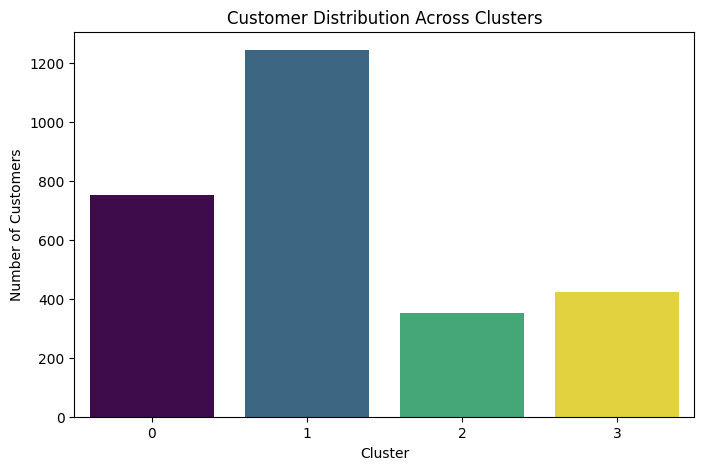

In [16]:
cluster_counts = rfm["Cluster"].value_counts().sort_index()

print("Customers per Cluster:")
print(cluster_counts)

plt.figure(figsize=(8, 5))

sns.countplot(
    data=rfm,
    x="Cluster",
    hue="Cluster",
    palette="viridis",
    legend=False
)

plt.title("Customer Distribution Across Clusters")
plt.xlabel("Cluster")
plt.ylabel("Number of Customers")

plt.show()

In [17]:
cluster_profile = rfm.groupby("Cluster").agg(
    CustomerCount=("CustomerID", "count"),
    AvgRecency=("Recency", "mean"),
    AvgFrequency=("Frequency", "mean"),
    AvgMonetary=("Monetary", "mean"),
    MedianRecency=("Recency", "median"),
    MedianFrequency=("Frequency", "median"),
    MedianMonetary=("Monetary", "median")
).round(2)

display(cluster_profile)

,CustomerCount,AvgRecency,AvgFrequency,AvgMonetary,MedianRecency,MedianFrequency,MedianMonetary
Cluster,,,,,,,
0,753,56.56,2.98,1320.61,48.0,3.0,995.01
1,1243,103.90,1.15,284.67,104.0,1.0,251.56
2,353,13.31,9.48,5532.36,10.0,7.0,2571.67
3,423,12.72,1.94,589.31,12.0,2.0,471.11


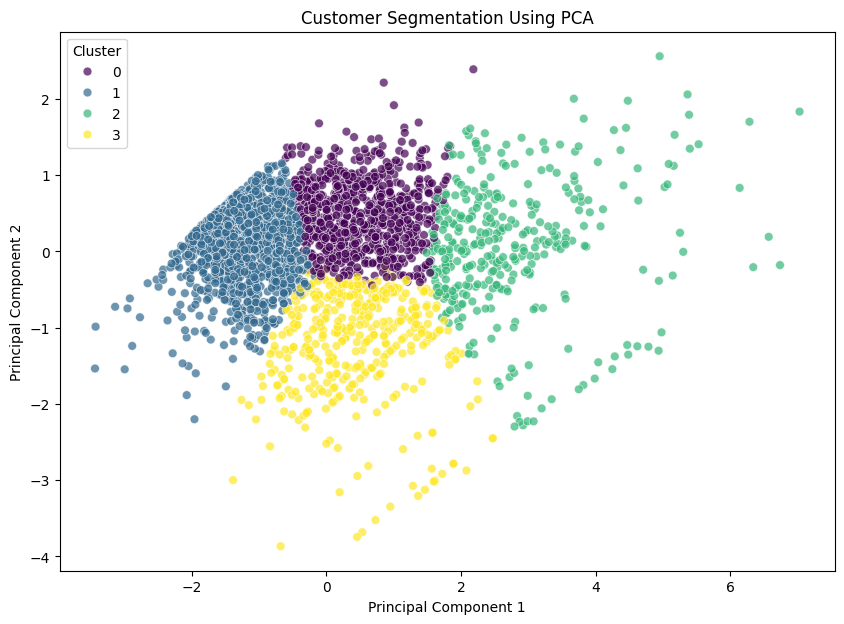

Explained Variance: 0.9185400659445815


In [18]:
pca = PCA(n_components=2)

pca_components = pca.fit_transform(rfm_scaled)

pca_df = pd.DataFrame(
    pca_components,
    columns=["PC1", "PC2"]
)

pca_df["Cluster"] = rfm["Cluster"].values

plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="Cluster",
    palette="viridis",
    s=40,
    alpha=0.7
)

plt.title("Customer Segmentation Using PCA")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.show()

print(
    "Explained Variance:",
    pca.explained_variance_ratio_.sum()
)

In [19]:
rfm["R_Score"] = (
    5 - pd.qcut(
        rfm["Recency"].rank(method="first"),
        5,
        labels=False
    )
)

rfm["F_Score"] = (
    1 + pd.qcut(
        rfm["Frequency"].rank(method="first"),
        5,
        labels=False
    )
)

rfm["M_Score"] = (
    1 + pd.qcut(
        rfm["Monetary"].rank(method="first"),
        5,
        labels=False
    )
)

rfm["RFM_Score"] = (
    rfm["R_Score"].astype(str) +
    rfm["F_Score"].astype(str) +
    rfm["M_Score"].astype(str)
)

rfm["Total_RFM_Score"] = (
    rfm["R_Score"] +
    rfm["F_Score"] +
    rfm["M_Score"]
)

rfm.head()

,CustomerID,Recency,Frequency,Monetary,Cluster,R_Score,F_Score,M_Score,RFM_Score,Total_RFM_Score
45307,12347.0,29,3,1603.68,0,4,4,5,445,13
45308,12348.0,148,1,367.00,1,1,1,3,113,5
45309,12352.0,162,2,280.66,1,1,3,2,132,6
45310,12353.0,104,1,89.00,1,2,1,1,211,4
45311,12354.0,132,1,1079.40,1,1,1,4,114,6


Combined Dataset Shape: (2772, 11)


,Cluster,Churn90D,ChurnRate
0,0,0.260292,26.029216
1,1,0.560740,56.074014
2,2,0.062323,6.232295
3,3,0.411348,41.134752


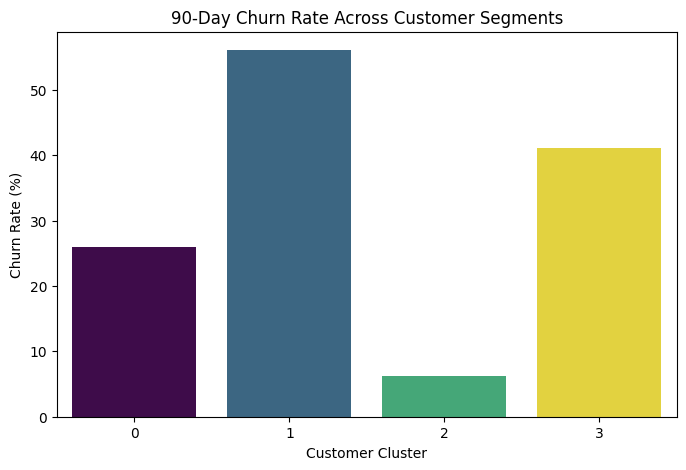

In [22]:
# Keep the churn label separate from clustering

customer_churn = customer_data[
    ["CustomerID", "Churn90D"]
].copy()

segmented_customers = rfm.merge(
    customer_churn,
    on="CustomerID",
    how="left"
)

print("Combined Dataset Shape:", segmented_customers.shape)

# Calculate the churn rate per cluster
cluster_churn = segmented_customers.groupby("Cluster")["Churn90D"].mean().reset_index()
cluster_churn["ChurnRate"] = cluster_churn["Churn90D"] * 100

display(cluster_churn)

#visual
plt.figure(figsize=(8, 5))

sns.barplot(
    data=cluster_churn,
    x="Cluster",
    y="ChurnRate",
    hue="Cluster",
    palette="viridis",
    legend=False
)

plt.title("90-Day Churn Rate Across Customer Segments")
plt.xlabel("Customer Cluster")
plt.ylabel("Churn Rate (%)")

plt.show()

In [25]:
segmented_customers.to_csv(
   "/customer_segments.csv",
    index=False
)

cluster_profile.to_csv(
     "/cluster_profile.csv"
)

cluster_churn.to_csv(
     "/cluster_churn_analysis.csv"
)

print("Customer segmentation files saved successfully!")

Customer segmentation files saved successfully!
